# Fiabilité des liaisons TGV

Question : peut-on construire un score de fiabilité par liaison, combinant la fréquence des annulations et l'ampleur des retards, puis le représenter sur un schéma du réseau ?

Réponse : oui. On calcule une note sur 100 pour chaque liaison, puis on la montre sur un schéma du réseau, dans un classement et dans quelques graphiques.

Données : https://ressources.data.sncf.com/explore/dataset/regularite-mensuelle-tgv-aqst/

Plan :
1. Données
2. Traitement des données
3. Calculer la note de chaque liaison
4. Schéma du réseau
5. Classement
6. Annulations et retards
7. La note est-elle robuste ?
8. Conclusion

## 1. Données

Modifiez ces valeurs, puis relancez le carnet à partir de cette cellule.

In [1]:
PERIODE_DEBUT = None # "AAAA-MM". None = depuis le début des données
PERIODE_FIN = None  # "AAAA-MM". None = jusqu'à la fin des données
MIN_TRAINS = 100           

POIDS = 0.5
CAP_ANNULATION = 6.0
CAP_RETARD = 12.0

FICHIER_LOCAL = "../data/raw/regularite-mensuelle-tgv-aqst.csv"

## 2. Traitement des données

In [2]:
import networkx as nx
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

brut = pd.read_csv(FICHIER_LOCAL, sep=";")
print(len(brut), "lignes,", brut.shape[1], "colonnes")
brut.head()

12907 lignes, 26 colonnes


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


In [3]:
brut.describe()

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
count,12907.000000,12907.000000,12907.000000,0.0,12907.000000,12907.000000,12907.000000,0.0,12907.000000,12907.000000,...,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000
mean,170.693112,273.443635,8.273650,NaN,86.703882,12.598479,3.218180,NaN,38.874797,35.618496,...,28.101418,37.044197,13.328349,5.490819,22.204867,21.071536,19.690203,19.097682,8.177636,7.646645
std,87.726724,184.117868,21.805356,NaN,88.749586,11.584859,5.016502,NaN,32.454431,15.611291,...,23.911428,19.334086,13.030851,6.388148,16.211847,14.998078,14.926445,13.618080,9.302347,9.504751
min,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,-229.269444,NaN,0.000000,-40.109259,...,0.000000,-4.000000,-44.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,99.000000,151.000000,0.000000,NaN,22.000000,6.432137,1.250273,NaN,16.000000,26.091113,...,11.000000,29.084910,4.000000,1.000000,10.937500,11.111111,9.090909,10.000000,0.000000,0.000000
50%,163.000000,231.000000,2.000000,NaN,52.000000,10.696078,2.400417,NaN,30.000000,33.895833,...,22.000000,38.232979,10.000000,3.000000,20.000000,19.631094,18.181818,17.307692,6.122449,5.128205
75%,223.000000,365.000000,7.000000,NaN,127.000000,16.231349,4.094720,NaN,53.000000,42.912828,...,38.000000,47.664250,18.000000,7.000000,30.769231,28.888889,28.070175,25.806452,11.764706,11.111111
max,786.000000,1104.000000,297.000000,NaN,598.000000,316.188095,115.047390,NaN,376.000000,299.600000,...,312.000000,299.600000,202.000000,77.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


Chaque ligne correspond à une liaison pour un mois : gare de départ, gare d'arrivée, nombre de trains prévus, nombre de trains annulés, retards.

Une liaison est une paire de gares. L'ordre n'a pas d'importance.

Pour chaque liaison pour un mois, on a la moyenne des retards. La somme des moyenne n'est pas une moyenne. Donc on doit reconvertir en minutes de retards, pour calculer la moyenne après le groupby.

In [4]:
data = pd.DataFrame({
    "date": pd.to_datetime(brut["Date"]),
    "depart": brut["Gare de départ"].str.strip().str.title(),
    "arrivee": brut["Gare d'arrivée"].str.strip().str.title(),
    "prevus": pd.to_numeric(brut["Nombre de circulations prévues"]),
    "annules": pd.to_numeric(brut["Nombre de trains annulés"]),
    "retard_tous": pd.to_numeric(brut["Retard moyen de tous les trains à l'arrivée"]),
})

data = data[data["prevus"] > 0].copy()
data["circules"] = data["prevus"] - data["annules"]
data["minutes_retard"] = data["retard_tous"] * data["circules"]

data["gare_a"] = data[["depart", "arrivee"]].min(axis=1)
data["gare_b"] = data[["depart", "arrivee"]].max(axis=1)
data["mois"] = data["date"].dt.to_period("M").astype(str)

aretes_fichier = sorted(set(zip(data["gare_a"], data["gare_b"])))

if PERIODE_DEBUT:
    data = data[data["mois"] >= PERIODE_DEBUT]
if PERIODE_FIN:
    data = data[data["mois"] <= PERIODE_FIN]

print("Période :", data["mois"].min(), "à", data["mois"].max())
print("Nombre de liaisons (deux sens regroupés) :", len(aretes_fichier))
data.head()

Période : 2018-01 à 2026-09
Nombre de liaisons (deux sens regroupés) : 65


,date,depart,arrivee,prevus,annules,retard_tous,circules,minutes_retard,gare_a,gare_b,mois
0,2018-01-01,Bordeaux St Jean,Paris Montparnasse,870,5,6.511118,865,5632.116667,Bordeaux St Jean,Paris Montparnasse,2018-01
1,2018-01-01,Le Mans,Paris Montparnasse,406,1,5.363539,405,2172.233333,Le Mans,Paris Montparnasse,2018-01
2,2018-01-01,Paris Montparnasse,La Rochelle Ville,226,0,2.938053,226,664.000000,La Rochelle Ville,Paris Montparnasse,2018-01
3,2018-01-01,Paris Montparnasse,Nantes,508,3,5.292211,505,2672.566667,Nantes,Paris Montparnasse,2018-01
4,2018-01-01,Poitiers,Paris Montparnasse,472,4,4.882372,468,2284.950000,Paris Montparnasse,Poitiers,2018-01


## 3. Calculer la note de chaque liaison

On calcule deux indicateurs pour chaque liaison.

Taux d'annulation : nombre de trains supprimés divisé par le nombre de trains prévus.

Retard moyen : retard moyen à l'arrivée de tous les trains qui ont circulé. Un train à l'heure compte pour 0 minute. En moyenne, de combien de minutes un train est-il en retard ?

Ces deux indicateurs n'ont pas la même unité (pourcentage et minutes). On les normalise, chacun à une échelle de 0 à 1. 0=aucun problème. 1=un taux d'annulation de CAP_ANNULATION ou plus, ou un retard moyen de CAP_RETARD ou plus. Ces deux seuils sont des choix que l'on peut modifier.

Formule:

Note = 100 x (1 - POIDS x échelle annulations - (1 - POIDS) x échelle retards)

Le choix POIDS=0.5 est un choix arbitraire modifiable. Ce choix sera examiné après.

Une liaison sans annulation ni retard obtient 100. Une liaison au pire niveau sur les deux critères obtient 0.

Catégories : très fiable (85 et plus), fiable (70 à 84), moyenne (55 à 69), peu fiable (40 à 54), à risque (moins de 40).

Le choix du seuil des catégories est aussi arbitraire.

In [5]:
# Catégories : nom, note minimale, couleur (bleu vers rouge, lisible par les daltoniens)
CATEGORIES = [
    ("Très fiable", 85, "#1f5fa8"),
    ("Fiable", 70, "#74b3d9"),
    ("Moyenne", 55, "#f2d04b"),
    ("Peu fiable", 40, "#f08a24"),
    ("À risque", -1, "#b2182b"),
]
ORDRE = [c[0] for c in CATEGORIES]
COULEUR = {c[0]: c[2] for c in CATEGORIES}


def categorie(note):
    for nom, seuil, _ in CATEGORIES:
        if note >= seuil:
            return nom
    return "À risque"


def somme_par(t, colonnes):
    return t.groupby(colonnes, as_index=False)[["prevus", "annules", "circules", "minutes_retard"]].sum()


def ajouter_score(t, poids=POIDS, cap_annul=CAP_ANNULATION, cap_retard=CAP_RETARD):
    t = t.copy()
    t["taux_annulation"] = t["annules"] / t["prevus"] * 100
    t["retard_moyen"] = (t["minutes_retard"] / t["circules"].replace(0, np.nan))
    penalite_annul = (t["taux_annulation"] / cap_annul).clip(0, 1)
    penalite_retard = (t["retard_moyen"] / cap_retard).clip(0, 1)
    t["score"] = 100 * (1 - poids * penalite_annul - (1 - poids) * penalite_retard)
    t["categorie"] = t["score"].apply(categorie)
    return t


liaisons = somme_par(data, ["gare_a", "gare_b"])
liaisons = liaisons[liaisons["prevus"] >= MIN_TRAINS]
liaisons = ajouter_score(liaisons)
liaisons["liaison"] = liaisons["gare_a"] + " - " + liaisons["gare_b"]
liaisons = liaisons.sort_values("score", ascending=False).reset_index(drop=True)

total = liaisons[["prevus", "annules", "circules", "minutes_retard"]].sum().to_frame().T
reseau = ajouter_score(total).iloc[0]

print(len(liaisons), "liaisons analysées")
print("Trains supprimés :", round(reseau["taux_annulation"], 1), "sur 100")
print("Retard moyen à l'arrivée :", round(reseau["retard_moyen"], 1), "minutes")
print("Note globale du réseau :", round(reseau["score"]), "sur 100")
print("Trains prévus :", int(liaisons["prevus"].sum()))
print("Trains annulés :", int(liaisons["annules"].sum()))

liaisons[["liaison", "score", "categorie", "taux_annulation", "retard_moyen", "prevus"]].round(1).head(10)

65 liaisons analysées
Trains supprimés : 3.0 sur 100
Retard moyen à l'arrivée : 6.0 minutes
Note globale du réseau : 50 sur 100
Trains prévus : 3529337
Trains annulés : 106303


,liaison,score,categorie,taux_annulation,retard_moyen,prevus
0,Paris Vaugirard - Rennes,84.1,Fiable,0.0,3.8,629
1,Le Creusot Montceau Montchanin - Paris Lyon,71.1,Fiable,1.7,3.5,42357
2,Nantes - Paris Vaugirard,67.3,Moyenne,0.0,7.8,1201
3,Paris Est - Reims,66.9,Moyenne,2.5,3.0,44042
4,Lyon Part Dieu - Paris Lyon,63.5,Moyenne,2.3,4.2,129942
5,Nancy - Paris Est,62.4,Moyenne,2.7,3.6,56609
6,Laval - Paris Montparnasse,62.3,Moyenne,2.3,4.4,50940
7,Dijon Ville - Paris Lyon,62.1,Moyenne,2.5,4.1,76613
8,Metz - Paris Est,60.6,Moyenne,2.5,4.4,57069
9,Le Mans - Paris Montparnasse,59.9,Moyenne,2.7,4.2,89538


## 4. Schéma du réseau

La position des gares est calculée par un algorithme de dessin de graphe : les gares reliées entre elles sont rapprochées. Les distances sur le dessin ne correspondent donc pas à des kilomètres. La position est calculée sur toutes les liaisons du fichier, pour que le dessin reste le même quand on change les réglages.

On pourrait avoir des distances plus réalistes si on estime les distances par le temps du trajet. Mais le graphe serait moins lisible.

(Cette section a été réalisé avec l'aide de l'IA et la librairie networkx)

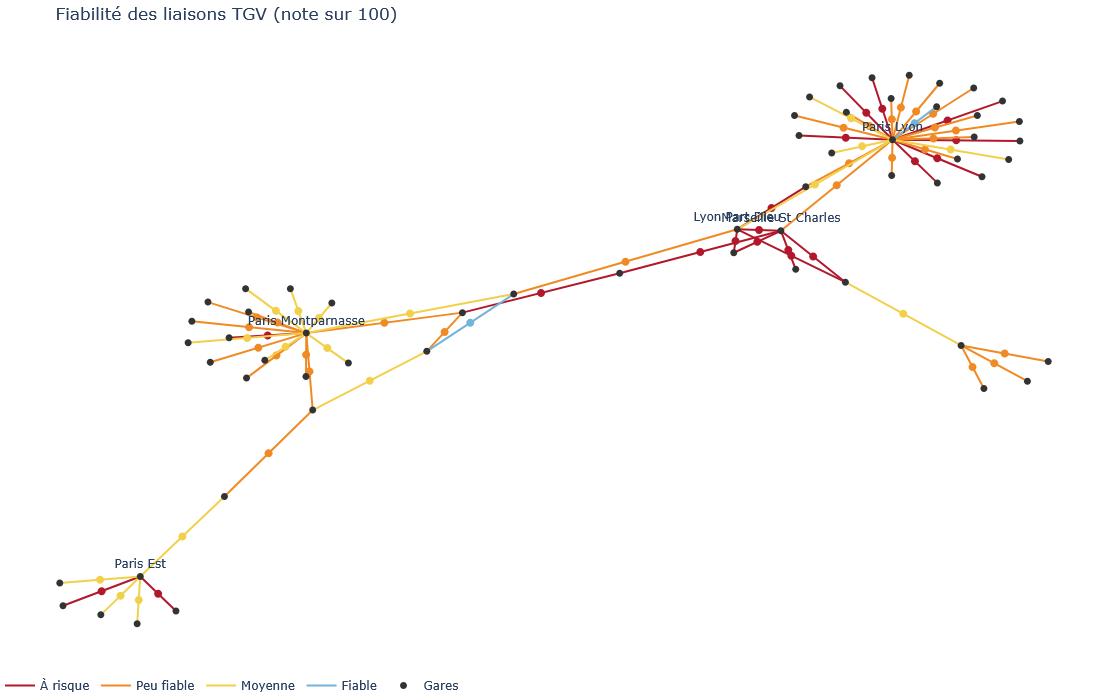

In [6]:
#focus sur une gare et ses liasons. None pour toutes les gares
GARE_A_SUIVRE = None 

graphe = nx.Graph()
graphe.add_edges_from(aretes_fichier)
positions = nx.spring_layout(graphe, seed=3, iterations=200)

if GARE_A_SUIVRE is None:
    affichees = liaisons
else:
    affichees = liaisons[(liaisons["gare_a"] == GARE_A_SUIVRE) | (liaisons["gare_b"] == GARE_A_SUIVRE)]
    print(len(affichees), "liaison(s) pour", GARE_A_SUIVRE)

fig = go.Figure()
for cat in reversed(ORDRE):
    sous = affichees[affichees["categorie"] == cat]
    if sous.empty:
        continue
    x, y = [], []
    for _, r in sous.iterrows():
        xa, ya = positions[r["gare_a"]]
        xb, yb = positions[r["gare_b"]]
        x += [xa, xb, None]
        y += [ya, yb, None]
    fig.add_trace(go.Scatter(x=x, y=y, mode="lines", line=dict(width=2, color=COULEUR[cat]),
                             name=cat, hoverinfo="skip"))

    milieux_x = [(positions[a][0] + positions[b][0]) / 2 for a, b in zip(sous["gare_a"], sous["gare_b"])]
    milieux_y = [(positions[a][1] + positions[b][1]) / 2 for a, b in zip(sous["gare_a"], sous["gare_b"])]
    textes = [
        f"{r['liaison']}<br>Note : {r['score']:.0f} sur 100 ({r['categorie']})"
        f"<br>Trains supprimés : {r['taux_annulation']:.1f} sur 100"
        f"<br>Retard moyen : {r['retard_moyen']:.1f} min"
        f"<br>Trains prévus : {int(r['prevus'])}"
        for _, r in sous.iterrows()
    ]
    fig.add_trace(go.Scatter(x=milieux_x, y=milieux_y, mode="markers", marker=dict(size=8, color=COULEUR[cat]),
                             text=textes, hoverinfo="text", showlegend=False))

gares_affichees = sorted(set(affichees["gare_a"]) | set(affichees["gare_b"]))
nb_liaisons = pd.concat([affichees["gare_a"], affichees["gare_b"]]).value_counts()
noms = [g if (nb_liaisons[g] >= 5 or GARE_A_SUIVRE is not None) else "" for g in gares_affichees]
fig.add_trace(go.Scatter(
    x=[positions[g][0] for g in gares_affichees], y=[positions[g][1] for g in gares_affichees],
    mode="markers+text", text=noms, textposition="top center", marker=dict(size=7, color="#333333"),
    hovertext=[f"{g} : {nb_liaisons[g]} liaison(s)" for g in gares_affichees],
    hoverinfo="text", name="Gares"))

fig.update_layout(title="Fiabilité des liaisons TGV (note sur 100)", height=700, plot_bgcolor="white",
                  margin=dict(l=0, r=0, t=40, b=0), xaxis=dict(visible=False), yaxis=dict(visible=False),
                  legend=dict(orientation="h", y=-0.02))
fig.show()

## 5. Classement

Les barres montrent la note sur 100 des liaisons les plus fiables et des moins fiables.

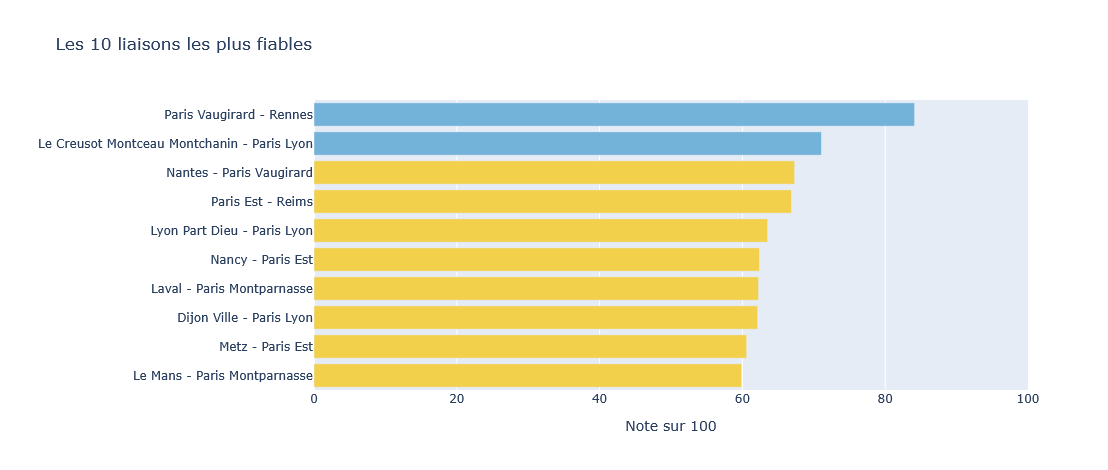

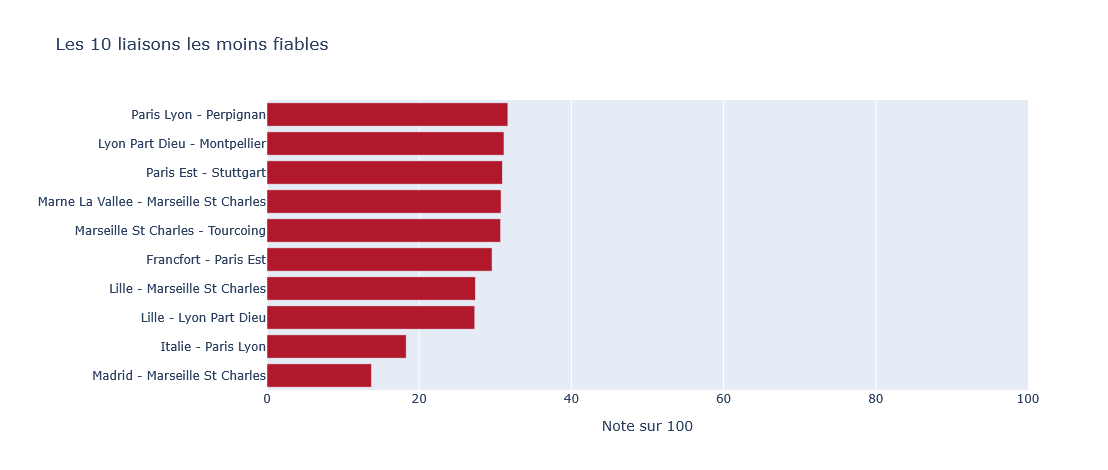

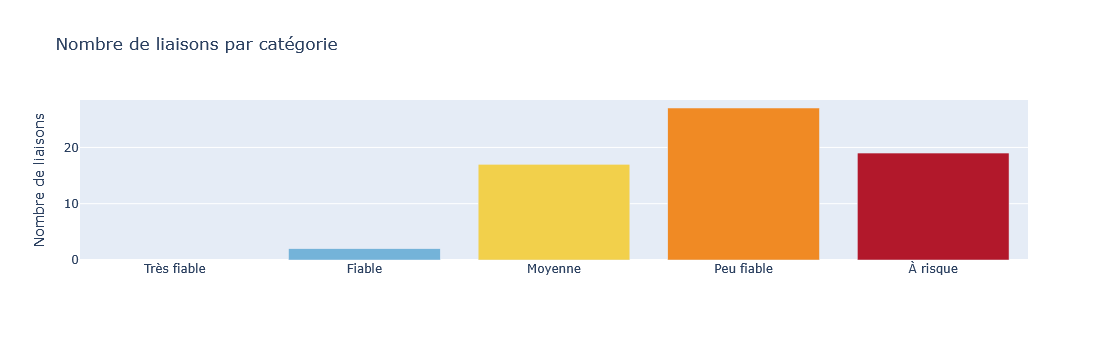

In [7]:
N = 10


def barres(t, titre):
    t = t.iloc[::-1]
    f = px.bar(t, x="score", y="liaison", orientation="h", color="categorie",
               color_discrete_map=COULEUR, range_x=[0, 100], title=titre,
               labels={"score": "Note sur 100", "liaison": ""},
               hover_data={"taux_annulation": ":.1f", "retard_moyen": ":.1f", "categorie": False})
    f.update_layout(showlegend=False, height=35 * len(t) + 120)
    return f


barres(liaisons.head(N), f"Les {N} liaisons les plus fiables").show()
barres(liaisons.tail(N), f"Les {N} liaisons les moins fiables").show()

repartition = liaisons["categorie"].value_counts().reindex(ORDRE).reset_index()
repartition.columns = ["categorie", "nombre"]
f = px.bar(repartition, x="categorie", y="nombre", color="categorie", color_discrete_map=COULEUR,
           title="Nombre de liaisons par catégorie", labels={"categorie": "", "nombre": "Nombre de liaisons"})
f.update_layout(showlegend=False, height=340)
f.show()

## 6. Annulations et retards

Ce graphique permet de voir si la note d'une liaison est davantage pénalisée par les annulations ou par les retards. La taille d'un point est proportionnelle au nombre de trains prévus.

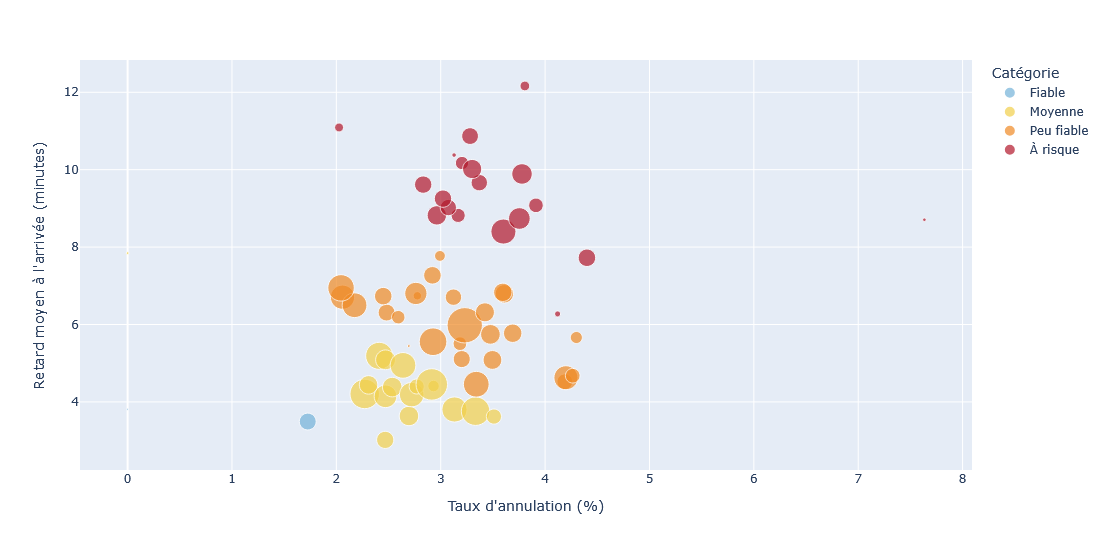

Exemple : Paris Lyon - Valence Alixan Tgv
2.8 trains supprimés sur 100 et 6.8 minutes de retard moyen.
Note = 100 - 23 points (annulations) - 28 points (retards) = 49 sur 100


In [8]:
f = px.scatter(liaisons, x="taux_annulation", y="retard_moyen", color="categorie",
               color_discrete_map=COULEUR, category_orders={"categorie": ORDRE},
               size="prevus", size_max=25, hover_name="liaison",
               hover_data={"score": ":.0f", "taux_annulation": ":.1f", "retard_moyen": ":.1f",
                           "prevus": True, "categorie": False},
               labels={"taux_annulation": "Taux d'annulation (%)",
                       "retard_moyen": "Retard moyen à l'arrivée (minutes)", "categorie": "Catégorie"})
f.update_layout(height=550)
f.show()

# Un exemple concret, pris au milieu du classement
ex = liaisons.iloc[len(liaisons) // 2]
pts_annul = min(ex["taux_annulation"] / CAP_ANNULATION, 1) * POIDS * 100
pts_retard = min(ex["retard_moyen"] / CAP_RETARD, 1) * (1 - POIDS) * 100
print("Exemple :", ex["liaison"])
print(f"{ex['taux_annulation']:.1f} trains supprimés sur 100 et {ex['retard_moyen']:.1f} minutes de retard moyen.")
print(f"Note = 100 - {pts_annul:.0f} points (annulations) - {pts_retard:.0f} points (retards) = {ex['score']:.0f} sur 100")

## 7. La note est-elle robuste ?

Le poids 50/50 et les seuils sont des choix. Si le classement changeait complètement dès qu'on les modifie, la note serait peu utile. On calcule donc la note avec plusieurs variantes, puis on compare les classements.

La corrélation vaut 1 si le classement est identique à la référence. Plus elle est proche de 1, plus le classement est stable.

In [9]:
variantes = {
    "Référence": dict(poids=POIDS, cap_annul=CAP_ANNULATION, cap_retard=CAP_RETARD),
    "Annulations plus importantes": dict(poids=0.7, cap_annul=CAP_ANNULATION, cap_retard=CAP_RETARD),
    "Retards plus importants": dict(poids=0.3, cap_annul=CAP_ANNULATION, cap_retard=CAP_RETARD),
    "Seuils deux fois plus stricts": dict(poids=POIDS, cap_annul=CAP_ANNULATION / 2, cap_retard=CAP_RETARD / 2),
    "Seuils deux fois plus larges": dict(poids=POIDS, cap_annul=CAP_ANNULATION * 2, cap_retard=CAP_RETARD * 2),
}

base_calcul = liaisons[["liaison", "prevus", "annules", "circules", "minutes_retard"]]
rangs = pd.DataFrame({
    nom: ajouter_score(base_calcul, **p).set_index("liaison")["score"].rank(ascending=False)
    for nom, p in variantes.items()
})

print("Corrélation des classements avec la référence (1 = identique) :")
for nom, valeur in rangs.corr()["Référence"].drop("Référence").items():
    print(f"  {nom} : {valeur:.2f}")

top_reference = set(rangs["Référence"].nsmallest(N).index)
print()
print(f"Parmi les {N} meilleures liaisons de la référence, combien restent dans les {N} meilleures :")
for nom in variantes:
    if nom != "Référence":
        communs = len(top_reference & set(rangs[nom].nsmallest(N).index))
        print(f"  {nom} : {communs} sur {N}")

Corrélation des classements avec la référence (1 = identique) :
  Annulations plus importantes : 0.95
  Retards plus importants : 0.96
  Seuils deux fois plus stricts : 0.92
  Seuils deux fois plus larges : 1.00

Parmi les 10 meilleures liaisons de la référence, combien restent dans les 10 meilleures :
  Annulations plus importantes : 9 sur 10
  Retards plus importants : 9 sur 10
  Seuils deux fois plus stricts : 9 sur 10
  Seuils deux fois plus larges : 10 sur 10


## 8. Conclusion

Oui, on peut construire un score de fiabilité par liaison et le représenter sur un schéma du réseau.

Limites :
* Le poids et les seuils sont des choix.
* Les données sont mensuelles. On ne voit pas la situation d'un train précis.
* Une grève ou une tempête peut baisser la note d'une liaison sur toute la période.
* Le schéma n'est pas géographique, car le jeu de données ne contient pas la position des gares.